# Employee Performance and Retention Analysis

## Executive Summary
This project analyzes employee performance and retention using HR data. It includes data cleaning, preprocessing, exploratory data analysis (EDA), key metrics analysis, employee performance analysis, retention trends, and business recommendations to support HR decision-making.

## Data Loading and Library Import

This section imports the required Python libraries and loads the employee dataset into a Pandas DataFrame.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
df = pd.read_csv("../data/employees_dataset.csv")

In [3]:
df.head()

,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met_more_than_80,awards_won,avg_training_score
0,8724,Technology,region_26,Bachelors,m,sourcing,1,24,NaN,1,1,0,77
1,74430,HR,region_4,Bachelors,f,other,1,31,3.0,5,0,0,51
2,72255,Sales & Marketing,region_13,Bachelors,m,other,1,31,1.0,4,0,0,47
3,38562,Procurement,region_2,Bachelors,f,other,3,31,2.0,9,0,0,65
4,64486,Finance,region_29,Bachelors,m,sourcing,1,30,4.0,7,0,0,61


In [4]:
df.shape

(17417, 13)

In [5]:
df.columns


Index(['employee_id', 'department', 'region', 'education', 'gender',
       'recruitment_channel', 'no_of_trainings', 'age', 'previous_year_rating',
       'length_of_service', 'KPIs_met_more_than_80', 'awards_won',
       'avg_training_score'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17417 entries, 0 to 17416
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   employee_id            17417 non-null  int64  
 1   department             17417 non-null  str    
 2   region                 17417 non-null  str    
 3   education              16646 non-null  str    
 4   gender                 17417 non-null  str    
 5   recruitment_channel    17417 non-null  str    
 6   no_of_trainings        17417 non-null  int64  
 7   age                    17417 non-null  int64  
 8   previous_year_rating   16054 non-null  float64
 9   length_of_service      17417 non-null  int64  
 10  KPIs_met_more_than_80  17417 non-null  int64  
 11  awards_won             17417 non-null  int64  
 12  avg_training_score     17417 non-null  int64  
dtypes: float64(1), int64(7), str(5)
memory usage: 1.7 MB


In [7]:
df.isnull().sum()

employee_id                 0
department                  0
region                      0
education                 771
gender                      0
recruitment_channel         0
no_of_trainings             0
age                         0
previous_year_rating     1363
length_of_service           0
KPIs_met_more_than_80       0
awards_won                  0
avg_training_score          0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(2)

In [9]:
df.describe()

,employee_id,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met_more_than_80,awards_won,avg_training_score
count,17417.000000,17417.000000,17417.000000,16054.000000,17417.000000,17417.000000,17417.000000,17417.000000
mean,39083.491129,1.250732,34.807774,3.345459,5.801860,0.358845,0.023368,63.176322
std,22707.024087,0.595692,7.694046,1.265386,4.175533,0.479675,0.151074,13.418179
min,3.000000,1.000000,20.000000,1.000000,1.000000,0.000000,0.000000,39.000000
25%,19281.000000,1.000000,29.000000,3.000000,3.000000,0.000000,0.000000,51.000000
50%,39122.000000,1.000000,33.000000,3.000000,5.000000,0.000000,0.000000,60.000000
75%,58838.000000,1.000000,39.000000,4.000000,7.000000,1.000000,0.000000,75.000000
max,78295.000000,9.000000,60.000000,5.000000,34.000000,1.000000,1.000000,99.000000


In [10]:
df.nunique()

employee_id              17414
department                   9
region                      34
education                    3
gender                       2
recruitment_channel          3
no_of_trainings              9
age                         41
previous_year_rating         5
length_of_service           34
KPIs_met_more_than_80        2
awards_won                   2
avg_training_score          61
dtype: int64

In [11]:
df.dtypes

employee_id                int64
department                   str
region                       str
education                    str
gender                       str
recruitment_channel          str
no_of_trainings            int64
age                        int64
previous_year_rating     float64
length_of_service          int64
KPIs_met_more_than_80      int64
awards_won                 int64
avg_training_score         int64
dtype: object

In [12]:
df["department"].unique()

<StringArray>
[       'Technology',                'HR', 'Sales & Marketing',
       'Procurement',           'Finance',         'Analytics',
        'Operations',             'Legal',               'R&D']
Length: 9, dtype: str

In [13]:
df["gender"].unique()

<StringArray>
['m', 'f']
Length: 2, dtype: str

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17417 entries, 0 to 17416
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   employee_id            17417 non-null  int64  
 1   department             17417 non-null  str    
 2   region                 17417 non-null  str    
 3   education              16646 non-null  str    
 4   gender                 17417 non-null  str    
 5   recruitment_channel    17417 non-null  str    
 6   no_of_trainings        17417 non-null  int64  
 7   age                    17417 non-null  int64  
 8   previous_year_rating   16054 non-null  float64
 9   length_of_service      17417 non-null  int64  
 10  KPIs_met_more_than_80  17417 non-null  int64  
 11  awards_won             17417 non-null  int64  
 12  avg_training_score     17417 non-null  int64  
dtypes: float64(1), int64(7), str(5)
memory usage: 1.7 MB


In [15]:
df.isnull().sum()

employee_id                 0
department                  0
region                      0
education                 771
gender                      0
recruitment_channel         0
no_of_trainings             0
age                         0
previous_year_rating     1363
length_of_service           0
KPIs_met_more_than_80       0
awards_won                  0
avg_training_score          0
dtype: int64

In [16]:
df["department"].unique()

<StringArray>
[       'Technology',                'HR', 'Sales & Marketing',
       'Procurement',           'Finance',         'Analytics',
        'Operations',             'Legal',               'R&D']
Length: 9, dtype: str

In [17]:
df["education"].unique()

<StringArray>
['Bachelors', 'Masters & above', nan, 'Below Secondary']
Length: 4, dtype: str

In [18]:
df["gender"].unique()


<StringArray>
['m', 'f']
Length: 2, dtype: str

In [19]:
df["recruitment_channel"].unique()

<StringArray>
['sourcing', 'other', 'referred']
Length: 3, dtype: str

In [20]:
df["region"].unique()

<StringArray>
['region_26',  'region_4', 'region_13',  'region_2', 'region_29',  'region_7',
 'region_22', 'region_16', 'region_17', 'region_24', 'region_11', 'region_27',
  'region_9', 'region_20', 'region_34', 'region_23',  'region_8', 'region_14',
 'region_31', 'region_19',  'region_5', 'region_28', 'region_15',  'region_3',
 'region_25', 'region_12', 'region_21', 'region_30', 'region_10', 'region_33',
 'region_32',  'region_6',  'region_1', 'region_18']
Length: 34, dtype: str

In [21]:
df.describe()

,employee_id,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met_more_than_80,awards_won,avg_training_score
count,17417.000000,17417.000000,17417.000000,16054.000000,17417.000000,17417.000000,17417.000000,17417.000000
mean,39083.491129,1.250732,34.807774,3.345459,5.801860,0.358845,0.023368,63.176322
std,22707.024087,0.595692,7.694046,1.265386,4.175533,0.479675,0.151074,13.418179
min,3.000000,1.000000,20.000000,1.000000,1.000000,0.000000,0.000000,39.000000
25%,19281.000000,1.000000,29.000000,3.000000,3.000000,0.000000,0.000000,51.000000
50%,39122.000000,1.000000,33.000000,3.000000,5.000000,0.000000,0.000000,60.000000
75%,58838.000000,1.000000,39.000000,4.000000,7.000000,1.000000,0.000000,75.000000
max,78295.000000,9.000000,60.000000,5.000000,34.000000,1.000000,1.000000,99.000000


In [22]:
df.shape[0]

17417

In [23]:
df["department"].nunique()

9

In [24]:
df["department"].value_counts()

department
Sales & Marketing    5458
Operations           3524
Procurement          2240
Technology           2199
Analytics            1697
HR                    833
Finance               802
Legal                 332
R&D                   332
Name: count, dtype: int64

In [25]:
df["gender"].value_counts()

gender
m    12314
f     5103
Name: count, dtype: int64

In [26]:
df["education"].value_counts()

education
Bachelors          11519
Masters & above     4841
Below Secondary      286
Name: count, dtype: int64

In [27]:
df["age"].mean()


np.float64(34.80777401389447)

In [28]:
df["length_of_service"].mean()

np.float64(5.80186025147844)

In [29]:
df["avg_training_score"].mean()

np.float64(63.17632198426824)

In [30]:
df["previous_year_rating"].mean()

np.float64(3.3454590756197833)

In [31]:
df["KPIs_met_more_than_80"].value_counts()

KPIs_met_more_than_80
0    11167
1     6250
Name: count, dtype: int64

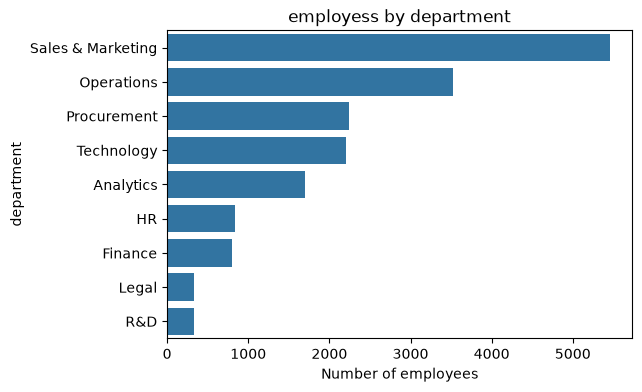

In [32]:
plt.figure(figsize = (6,4))
sns.countplot(data = df , y = "department" , order = df["department"].value_counts().index)
plt.title("employess by department")
plt.xlabel("Number of employees")
plt.ylabel("department")
plt.savefig("../images/employees by department.png",dpi = 300 , bbox_inches ="tight")
plt.show()

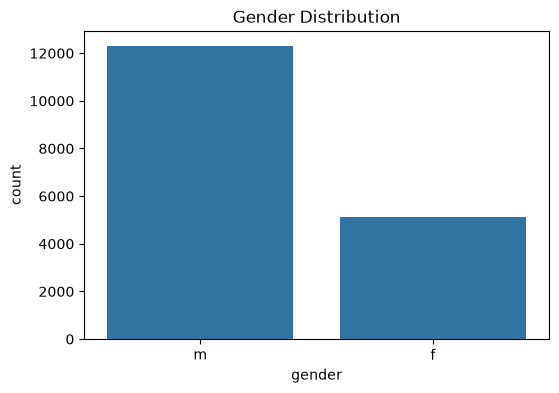

In [33]:
plt.figure(figsize=(6,4))
sns.countplot(data = df , x = "gender")
plt.title("Gender Distribution")
plt.savefig("../images/Gender distribution,png" , dpi =300 , bbox_inches = "tight")
plt.show()

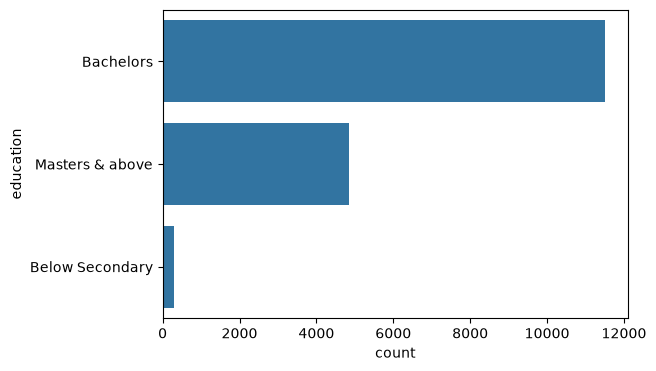

In [34]:
plt.figure(figsize=(6,4))
sns.countplot(data = df , y = "education")
plt.savefig("../images/education of employees.png" , dpi = 300 , bbox_inches = "tight")
plt.show()

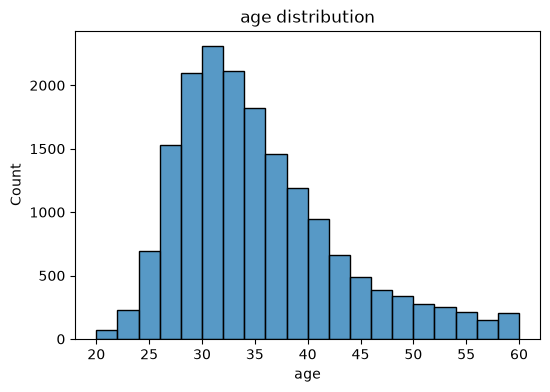

In [35]:
plt.figure(figsize=(6,4))
sns.histplot(df["age"],bins =20)
plt.title("age distribution")
plt.savefig("../images/age distribution.png" , dpi = 300 , bbox_inches = "tight")
plt.show()

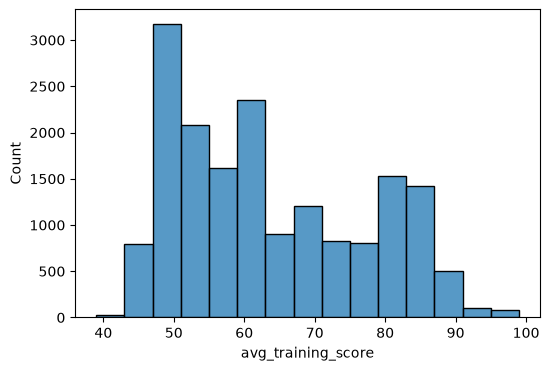

In [36]:
plt.figure(figsize=(6,4))
sns.histplot(df["avg_training_score"],bins=15)
plt.savefig("../images/training score of employees.png" , dpi = 300 , bbox_inches = "tight")
plt.show()

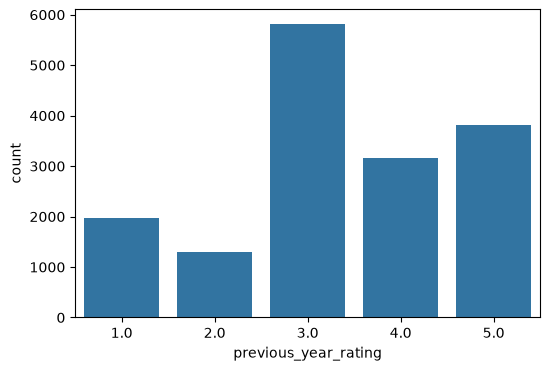

In [37]:
plt.figure(figsize=(6,4))
sns.countplot(data = df , x="previous_year_rating")
plt.savefig("../images/rating of employees.png" , dpi = 300 , bbox_inches = "tight")
plt.show()

In [38]:
df.groupby("department")["avg_training_score"].mean().sort_values(ascending=False)


department
Analytics            84.565115
R&D                  84.451807
Technology           79.847658
Procurement          70.180357
Operations           60.351589
Finance              60.326683
Legal                59.533133
HR                   50.387755
Sales & Marketing    50.056614
Name: avg_training_score, dtype: float64

In [39]:
df.groupby("department")["age"].mean().sort_values()

department
Analytics            32.405421
Finance              32.602244
R&D                  32.885542
Legal                33.750000
HR                   34.248499
Sales & Marketing    34.627153
Technology           35.034106
Operations           36.154086
Procurement          36.166964
Name: age, dtype: float64

In [40]:
df.groupby("department")["length_of_service"].mean().sort_values(ascending = False)

department
Operations           6.429342
Procurement          6.187500
Technology           5.844020
Sales & Marketing    5.753023
HR                   5.637455
Finance              5.009975
Analytics            4.998232
R&D                  4.798193
Legal                4.500000
Name: length_of_service, dtype: float64

In [41]:
df.groupby('education')["avg_training_score"].mean().sort_values(ascending= False)

education
Below Secondary    65.902098
Masters & above    64.134270
Bachelors          63.033336
Name: avg_training_score, dtype: float64

In [42]:
df.groupby("gender")["avg_training_score"].mean().round(2).sort_values(ascending=False)


gender
f    63.68
m    62.97
Name: avg_training_score, dtype: float64

In [43]:
df.groupby("department")["KPIs_met_more_than_80"].mean().sort_values(ascending=False)

department
R&D                  0.448795
Operations           0.440692
Analytics            0.400118
Finance              0.397756
Procurement          0.373214
HR                   0.360144
Technology           0.356071
Legal                0.355422
Sales & Marketing    0.277208
Name: KPIs_met_more_than_80, dtype: float64

In [44]:
df.groupby("department")["awards_won"].sum().sort_values(ascending=False)

department
Sales & Marketing    120
Operations            89
Technology            58
Procurement           57
Analytics             43
Finance               15
HR                    14
Legal                  6
R&D                    5
Name: awards_won, dtype: int64

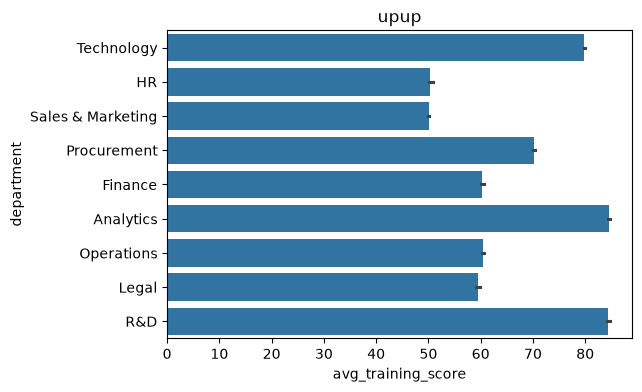

In [45]:
plt.figure(figsize =(6,4))
sns.barplot(
    data = df,
    x = "avg_training_score",
    y = "department" , 
    estimator = "mean"
)
plt.title("upup")
plt.savefig("../images/training score by department.png" , dpi = 300 , bbox_inches = "tight")
plt.show()

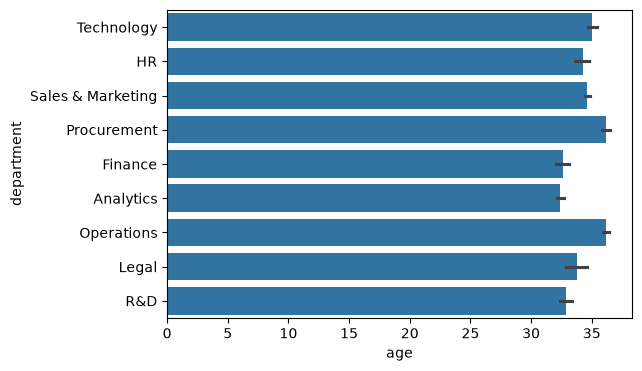

In [46]:
plt.figure(figsize=(6,4))
sns.barplot(data =df , y = "department" , x = "age" , estimator = "mean")
plt.savefig("../images/age of employees in department.png" , dpi = 300 , bbox_inches = "tight")
plt.show()


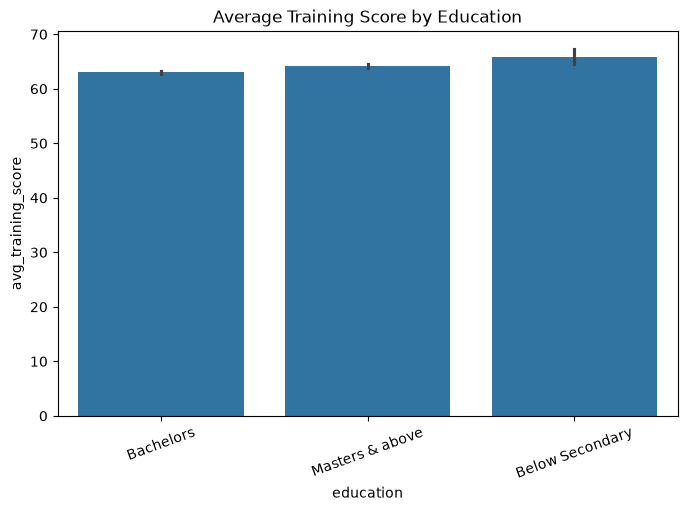

In [47]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=df,
    x="education",
    y="avg_training_score",
    estimator="mean"
)

plt.title("Average Training Score by Education")

plt.xticks(rotation=20)
plt.savefig("../images/training_score_by_department.png", dpi=300, bbox_inches="tight")
plt.show()

In [48]:
clean_df = df

In [49]:
clean_df.isnull().sum()

employee_id                 0
department                  0
region                      0
education                 771
gender                      0
recruitment_channel         0
no_of_trainings             0
age                         0
previous_year_rating     1363
length_of_service           0
KPIs_met_more_than_80       0
awards_won                  0
avg_training_score          0
dtype: int64

In [50]:
clean_df["education"].mode()


0    Bachelors
Name: education, dtype: str

In [51]:
clean_df["education"]=clean_df["education"].fillna(clean_df["education"].mode()[0])


In [52]:
clean_df["previous_year_rating"].describe()

count    16054.000000
mean         3.345459
std          1.265386
min          1.000000
25%          3.000000
50%          3.000000
75%          4.000000
max          5.000000
Name: previous_year_rating, dtype: float64

In [53]:
clean_df["previous_year_rating"]=clean_df["previous_year_rating"].fillna(clean_df["previous_year_rating"].mean())

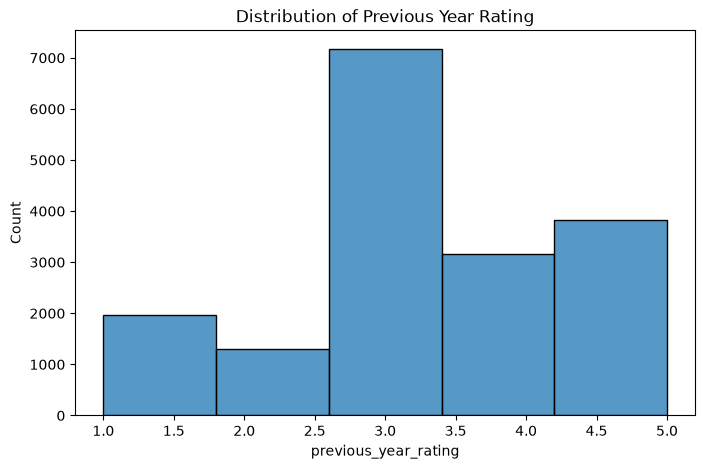

In [54]:
plt.figure(figsize=(8,5))
sns.histplot(clean_df["previous_year_rating"], bins=5)
plt.title("Distribution of Previous Year Rating")
plt.show()

In [55]:
clean_df.isnull().sum()

employee_id              0
department               0
region                   0
education                0
gender                   0
recruitment_channel      0
no_of_trainings          0
age                      0
previous_year_rating     0
length_of_service        0
KPIs_met_more_than_80    0
awards_won               0
avg_training_score       0
dtype: int64

In [56]:
clean_df.duplicated().sum()

np.int64(2)

In [57]:
clean_df = clean_df.drop_duplicates()

In [58]:
clean_df.dtypes

employee_id                int64
department                   str
region                       str
education                    str
gender                       str
recruitment_channel          str
no_of_trainings            int64
age                        int64
previous_year_rating     float64
length_of_service          int64
KPIs_met_more_than_80      int64
awards_won                 int64
avg_training_score         int64
dtype: object

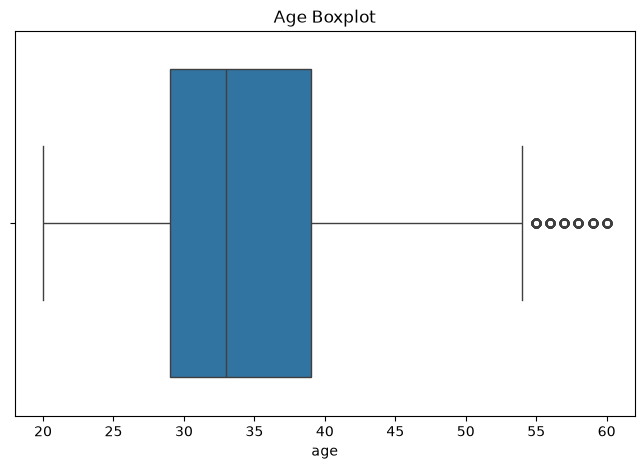

In [59]:
plt.figure(figsize=(8,5))
sns.boxplot(x=clean_df["age"])
plt.title("Age Boxplot")
plt.savefig("../images/avg age.png" , dpi = 300 , bbox_inches = "tight")
plt.show()

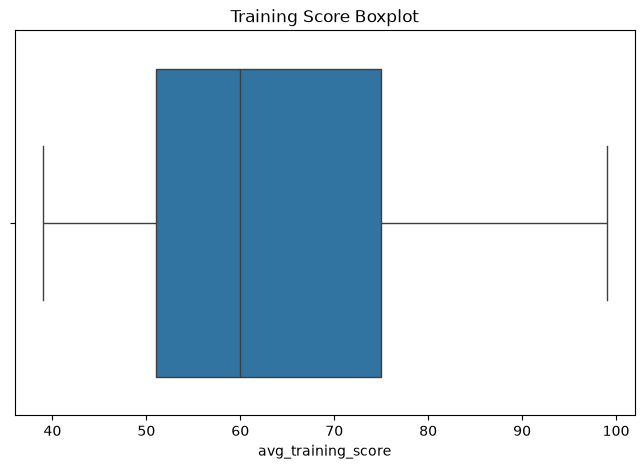

In [60]:
plt.figure(figsize=(8,5))
sns.boxplot(x=clean_df["avg_training_score"])
plt.title("Training Score Boxplot")
plt.savefig("../images/avg training score.png" , dpi = 300 , bbox_inches = "tight")
plt.show()


In [61]:
clean_df["experience_group"] = pd.cut(
    clean_df["length_of_service"],
    bins=[0, 5, 10, 20, 40],
    labels=["0-5 Years", "6-10 Years", "11-20 Years", "20+ Years"]
)

In [62]:
clean_df["age_group"] = pd.cut(
    clean_df["age"],
    bins=[20, 30, 40, 50, 60],
    labels=["20-30", "31-40", "41-50", "51-60"]
)

In [63]:
clean_df

,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met_more_than_80,awards_won,avg_training_score,experience_group,age_group
0,8724,Technology,region_26,Bachelors,m,sourcing,1,24,3.345459,1,1,0,77,0-5 Years,20-30
1,74430,HR,region_4,Bachelors,f,other,1,31,3.000000,5,0,0,51,0-5 Years,31-40
2,72255,Sales & Marketing,region_13,Bachelors,m,other,1,31,1.000000,4,0,0,47,0-5 Years,31-40
3,38562,Procurement,region_2,Bachelors,f,other,3,31,2.000000,9,0,0,65,6-10 Years,31-40
4,64486,Finance,region_29,Bachelors,m,sourcing,1,30,4.000000,7,0,0,61,6-10 Years,20-30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17410,57239,Sales & Marketing,region_31,Bachelors,m,other,1,42,3.000000,10,0,0,53,6-10 Years,41-50
17411,73858,Sales & Marketing,region_25,Bachelors,m,sourcing,2,28,2.000000,5,0,0,45,0-5 Years,20-30
17412,64573,Technology,region_7,Bachelors,f,referred,2,30,5.000000,6,1,0,81,6-10 Years,20-30
17413,49584,HR,region_7,Bachelors,m,other,1,33,1.000000,9,0,0,51,6-10 Years,31-40


In [64]:
department_performance = clean_df.groupby("department")[["previous_year_rating","avg_training_score"]].mean().round(2)
department_performance


,previous_year_rating,avg_training_score
department,,
Analytics,3.50,84.57
Finance,3.52,60.33
HR,3.55,50.39
Legal,3.43,59.53
Operations,3.65,60.35
Procurement,3.26,70.18
R&D,3.69,84.45
Sales & Marketing,3.13,50.06
Technology,3.17,79.85


In [65]:
education_performance = clean_df.groupby("education")[["previous_year_rating","avg_training_score"]].mean().round(2)
education_performance.sort_values(by = "avg_training_score" , ascending = False)

,previous_year_rating,avg_training_score
education,,
Below Secondary,3.51,65.90
Masters & above,3.37,64.13
Bachelors,3.33,62.74


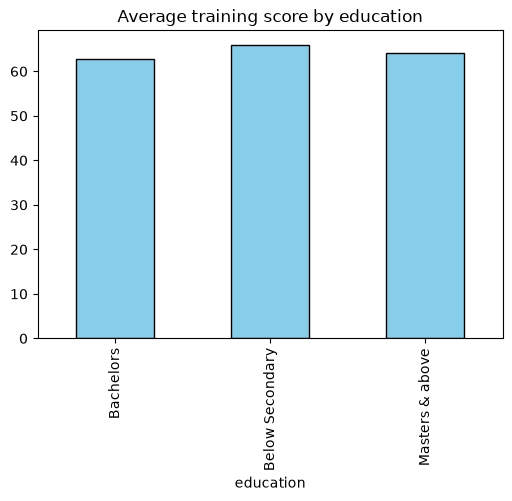

In [66]:
plt.figure(figsize=(6,4))
education_performance["avg_training_score"].plot(kind = "bar",color = "skyblue" , edgecolor = "black")
plt.title("Average training score by education")

plt.savefig("../images/educaton_training_score.png" , dpi = 300 )
plt.show()

In [67]:
gender_performance = clean_df.groupby("gender")[[
    "previous_year_rating",
    "avg_training_score"
]].mean().round(2)
gender_performance

,previous_year_rating,avg_training_score
gender,,
f,3.40,63.68
m,3.32,62.97


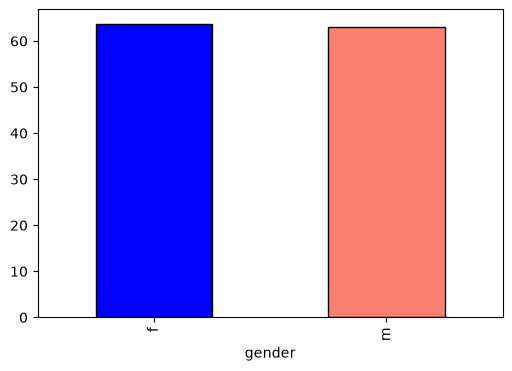

In [68]:
plt.figure(figsize=(6,4))
gender_performance["avg_training_score"].plot(
    kind = "bar",
    color = ["blue" , "salmon"],
    edgecolor = "black"
)
plt.savefig("../images/gender_performance.png" , dpi=300)
plt.show()

In [69]:
age_group_performance = clean_df.groupby("age_group")[[
    "avg_training_score",
    "previous_year_rating"
]].mean().round(2)
age_group_performance

,avg_training_score,previous_year_rating
age_group,,
20-30,63.79,3.32
31-40,63.16,3.35
41-50,61.89,3.36
51-60,63.25,3.40


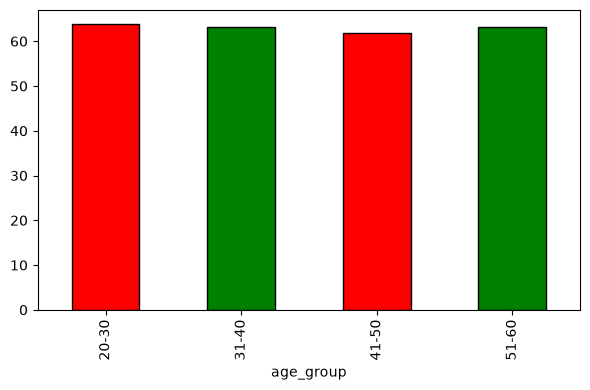

In [70]:
plt.figure(figsize=(6,4))
age_group_performance["avg_training_score"].plot(
    kind = "bar",
    color = ["red","green"],
    edgecolor = "black"
)
plt.savefig("../images/age_group_performance.png" , dpi = 300)
plt.tight_layout()
plt.show()


In [71]:
training_performance = clean_df.groupby("no_of_trainings")[[
    "previous_year_rating",
    "avg_training_score"
]].mean().round(2)
training_performance

,previous_year_rating,avg_training_score
no_of_trainings,,
1,3.37,62.79
2,3.28,65.03
3,3.16,64.22
4,2.90,62.68
5,3.30,66.58
6,2.96,62.25
7,2.39,63.67
8,4.50,71.00
9,3.50,70.00


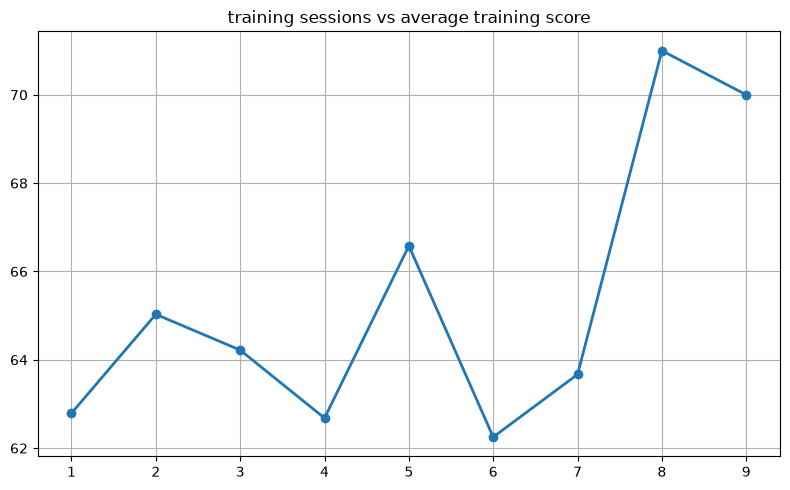

In [72]:
plt.figure(figsize=(8,5))
plt.plot(
    training_performance.index,
    training_performance["avg_training_score"],
    marker ="o",
    linewidth=2
)
plt.title("training sessions vs average training score")
plt.grid(True)
plt.tight_layout()
plt.savefig("../images/training_vs_performance.png",dpi=300)
plt.show()

In [73]:
service_distribution = clean_df["length_of_service"].describe()
service_distribution

count    17415.000000
mean         5.801493
std          4.175632
min          1.000000
25%          3.000000
50%          5.000000
75%          7.000000
max         34.000000
Name: length_of_service, dtype: float64

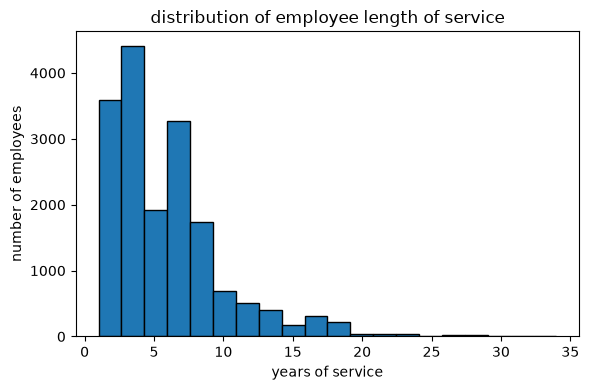

In [74]:
plt.figure(figsize=(6,4))
plt.hist(
    clean_df["length_of_service"],
    bins = 20,
    edgecolor="black"
)
plt.title("distribution of employee length of service")
plt.xlabel("years of service")
plt.ylabel("number of employees")
plt.tight_layout()
plt.savefig("../images/service_distribution.png",dpi=300)
plt.show()

In [75]:
department_retention = clean_df["department"].value_counts()
department_retention

department
Sales & Marketing    5458
Operations           3524
Procurement          2240
Technology           2199
Analytics            1697
HR                    831
Finance               802
Legal                 332
R&D                   332
Name: count, dtype: int64

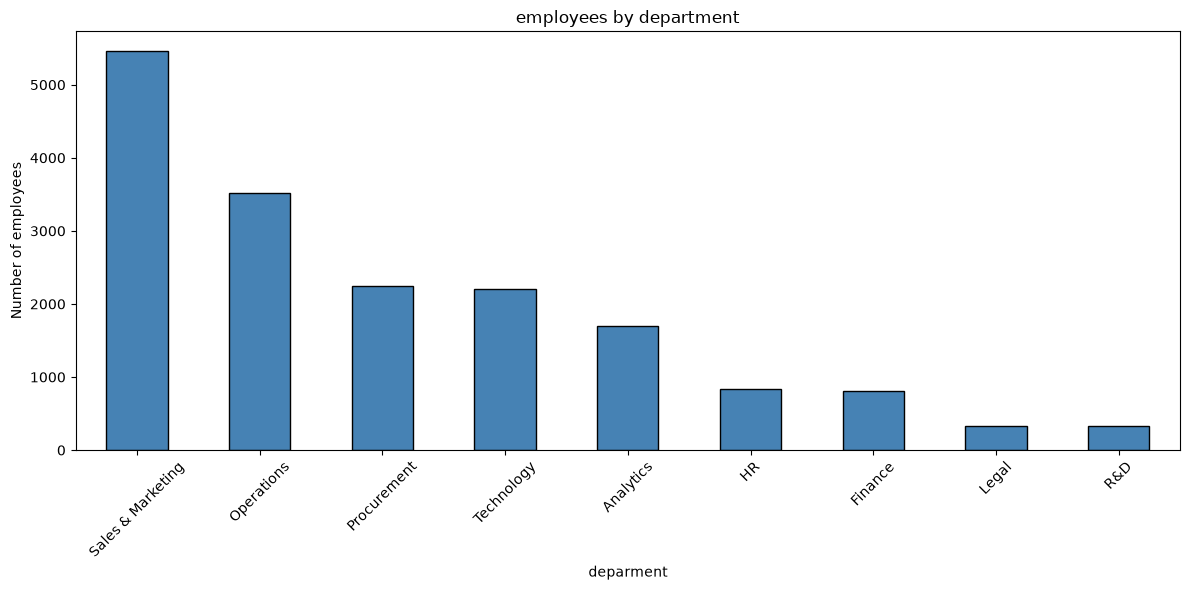

In [76]:
plt.figure(figsize=(12,6))
department_retention.plot(
    kind="bar",
    color="steelblue",
    edgecolor="black"
)
plt.title("employees by department")
plt.xlabel("deparment")
plt.ylabel("Number of employees")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../images/employees.png" , dpi =300)
plt.show()

In [77]:
age_distribution = clean_df["age_group"].value_counts().sort_index()
age_distribution

age_group
20-30    5746
31-40    8223
41-50    2474
51-60     930
Name: count, dtype: int64

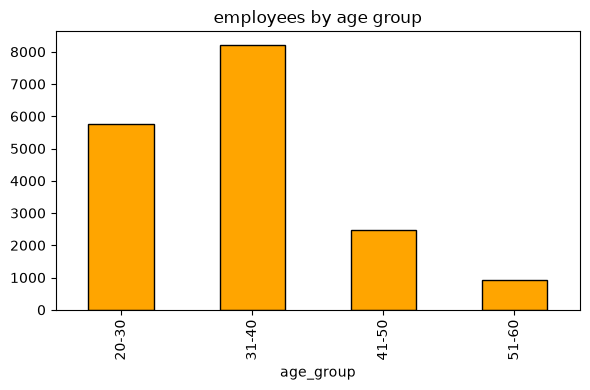

In [78]:
plt.figure(figsize=(6,4))
age_distribution.plot(
    kind = "bar",
    color = "orange",
    edgecolor = "black"
)
plt.title("employees by age group")
plt.tight_layout()
plt.savefig("../images/age_distribution",dpi=300)
plt.show()

In [79]:
education_distribution = clean_df["education"].value_counts()
education_distribution 

education
Bachelors          12288
Masters & above     4841
Below Secondary      286
Name: count, dtype: int64

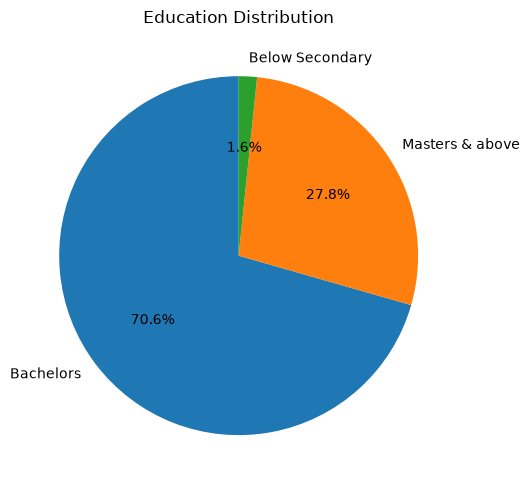

In [80]:
plt.figure(figsize=(8,5))
education_distribution.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Education Distribution")
plt.tight_layout()
plt.savefig("../images/education_distribution.png",dpi = 300)
plt.show()

In [81]:
training_distribution = clean_df["no_of_trainings"].value_counts().sort_index()
training_distribution

no_of_trainings
1    14059
2     2628
3      539
4      137
5       26
6       16
7        6
8        2
9        2
Name: count, dtype: int64

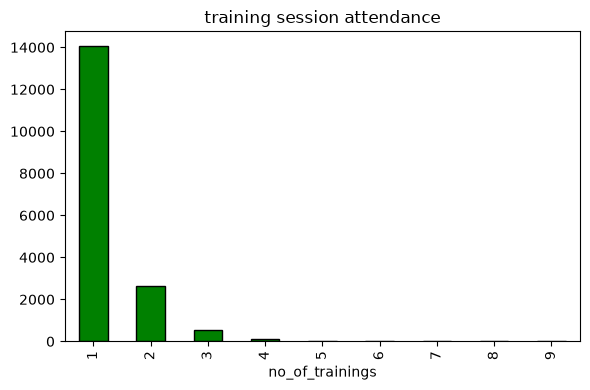

In [82]:
plt.figure(figsize=(6,4))
training_distribution.plot(
    kind="bar",
    color = "green",
    edgecolor = "black"
)
plt.title("training session attendance")
plt.tight_layout()
plt.savefig("../images/training_distribution.png" , dpi = 300)
plt.show()

In [83]:
dept_performance = (
  clean_df.groupby("department")["avg_training_score"].mean().sort_values(ascending=False)
)
dept_performance

department
Analytics            84.565115
R&D                  84.451807
Technology           79.847658
Procurement          70.180357
Operations           60.351589
Finance              60.326683
Legal                59.533133
HR                   50.386282
Sales & Marketing    50.056614
Name: avg_training_score, dtype: float64

In [84]:
region_performance = (clean_df.groupby("region")["avg_training_score"].mean().sort_values(ascending=False))
region_performance.head(10)

region
region_33    68.659341
region_5     68.047619
region_29    66.055195
region_10    65.808612
region_17    65.723881
region_26    65.346257
region_22    65.118593
region_8     64.995215
region_34    64.926829
region_24    64.624242
Name: avg_training_score, dtype: float64

In [85]:
kpi_rate=(
    clean_df["KPIs_met_more_than_80"].value_counts(normalize=True)*100
).round(2)
kpi_rate

KPIs_met_more_than_80
0    64.11
1    35.89
Name: proportion, dtype: float64

In [86]:
clean_df["awards_won"].value_counts()

awards_won
0    17008
1      407
Name: count, dtype: int64

In [87]:
important = clean_df[
    [ 
        "age",
        "length_of_service",
        "previous_year_rating",
        "avg_training_score"
    ]
]
important.corr()

,age,length_of_service,previous_year_rating,avg_training_score
age,1.000000,0.641171,0.017956,-0.028071
length_of_service,0.641171,1.000000,0.007550,-0.026343
previous_year_rating,0.017956,0.007550,1.000000,0.057961
avg_training_score,-0.028071,-0.026343,0.057961,1.000000


# Phase 7 – Predictive Insights & Recommendations

## Key Insights

- Employees with higher previous year ratings generally perform better in training.
- Departments with consistently higher training scores should be used as benchmarks.
- Employees attending more training sessions tend to achieve better average scores.
- KPI achievement is strongly associated with higher performance.
- Employees with awards usually maintain better performance records.

## HR Recommendations

### 1. Increase Training Opportunities
Provide additional training sessions for departments with lower average training scores.

### 2. Reward High Performers
Recognize employees who consistently meet KPIs through awards and incentives.

### 3. Focus on Low Performing Departments
Design department-specific improvement programs.

### 4. Employee Engagement
Conduct regular feedback sessions for employees with low ratings.

### 5. Career Development
Offer promotion pathways for consistently high-performing employees.

### 6. Data-Driven HR Decisions
Use employee performance metrics to identify future leaders and training requirements.

# Employee Performance and Retention Analysis

## Final Report

### Objective

The objective of this project was to analyze employee performance and retention using HR data. The analysis focused on identifying factors affecting employee productivity, training effectiveness, KPI achievement, and workforce retention.

The project involved data cleaning, exploratory data analysis, visualization, statistical analysis, and business recommendations for HR decision-making.

# Project Workflow

1. Data Collection
2. Data Cleaning
3. Exploratory Data Analysis
4. Performance Analysis
5. Retention Analysis
6. KPI & Training Analysis
7. Business Insights
8. HR Recommendations

# Major Findings

### Employee Performance

- Training score varies across departments.
- Previous year ratings positively influence employee performance.
- Employees meeting KPI targets generally perform better.
- Award-winning employees usually have higher training scores.

### Retention

- Employees with longer service are more stable.
- Training programs contribute positively to employee development.
- Certain departments require additional employee engagement initiatives.

### Training

- Higher training participation improves average performance.
- Departments with lower training scores should receive additional learning support.

# Business Recommendations

- Improve employee training programs.
- Recognize high-performing employees through incentives.
- Increase engagement in departments with lower performance.
- Use KPI tracking for promotion decisions.
- Monitor employee performance regularly using dashboards.
- Adopt data-driven HR policies for workforce planning.

# Conclusion

This project successfully analyzed employee performance and retention using Python.

The analysis identified important relationships between training, KPIs, previous performance ratings, and employee productivity.

The insights generated through exploratory data analysis and visualization can help HR managers improve workforce planning, employee engagement, and organizational performance.

Overall, this project demonstrates how data analytics can support strategic HR decision-making.

# Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook (VS Code)

# Thank You

# Conclusion

The analysis successfully explored employee demographics, training, KPI achievement, performance ratings, and retention-related indicators. The findings provide practical insights that HR teams can use to improve training programs, employee engagement, and overall workforce performance.

In [88]:
clean_df.to_csv("employees_clean.csv",index=False)